# Diamond Price Prediction

Predict a diamond's price from its certificate details and ship it as a live web app.

**Live app:** https://diamond-price-predictor-3cpqj68v7rma5o2aihmjpa.streamlit.app/

**Contents**
1. Problem framing
2. Data understanding
3. Cleaning and train/test split
4. Exploratory data analysis
5. Preprocessing pipeline
6. Baseline and candidate models
7. Hyperparameter tuning
8. Model and feature selection
9. Final test evaluation
10. Error analysis
11. Business insight
12. Saving the model for the app

# 1. Problem Framing

## 1. Who has the problem?
A jewelry retailer (or an online diamond marketplace) that buys and sells
thousands of diamonds. Pricing each stone by hand is slow and inconsistent,
and a wrong price either loses a sale (too high) or loses margin (too low).

## 2. What decision does the model support?
Given a diamond's physical characteristics (carat, cut, color, clarity,
dimensions), the model gives a fair-price estimate. The retailer uses it to:
- set an initial listing price for new stock,
- check whether a supplier's asking price is reasonable before buying.

## 3. Target variable
`price`: the diamond's price in US dollars (continuous, so this is a
regression problem).

## 4. Business metric: MAE (primary), with RMSE and R² as support
- **MAE** is the average dollar error per diamond. A retailer can read it
  directly ("on average we are off by $X").
- **RMSE** penalizes large errors more heavily. We report it too, because a
  big miss on an expensive stone costs far more than a small miss on a cheap one.
- **R²** shows how much of the price variation the model explains. It is a
  complement, not the main metric, because it does not say how many dollars
  we are off.
- **Baseline:** predicting the mean price for every diamond. Any real model
  must beat it clearly.


## 2. Data understanding

The dataset has 53,940 diamonds and 10 columns: price (target), carat, cut, color, clarity, depth, table, and the dimensions x, y, z (in mm). There are no missing values. Cut, color and clarity are ordered categories (for example, Fair is the lowest cut and Ideal the highest). Source: see the credit at the end of the notebook.

In [1]:
import pandas as pd
df = pd.read_csv("diamonds.csv")
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [2]:
df = df.drop(columns=["Unnamed: 0"])

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.7 MB


In [4]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [5]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(146)

In [7]:
print((df[["x", "y", "z"]] == 0).sum())

x     8
y     7
z    20
dtype: int64


In [8]:
# الصفوف اللي فيها أي بُعد = 0
print(df[(df.x == 0) | (df.y == 0) | (df.z == 0)].shape)

# الصفوف الغريبة في y و z
print(df[(df.y > 20) | (df.z > 20)][["carat", "x", "y", "z", "depth", "price"]])

(20, 10)
       carat     x      y      z  depth  price
24067   2.00  8.09  58.90   8.06   58.9  12210
48410   0.51  5.12   5.15  31.80   61.8   1970
49189   0.51  5.15  31.80   5.12   61.8   2075


## 3. Cleaning and train/test split

- **Impossible dimensions:** 23 rows have a length, width or depth of zero, or a width or depth above 20 mm. A diamond cannot have zero thickness, so these are data errors, and removing them uses a physical rule rather than a statistic from the data.
- **Duplicates:** exact duplicate rows are removed before splitting, so the same row can never appear in both train and test (data leakage).
- **Split:** 80% train / 20% test (43,017 / 10,755 rows), fixed random seed. The test set is not touched until the final evaluation.

In [9]:
import pandas as pd
import numpy as np

n_raw = len(df)

# 1) أبعاد مستحيلة فيزيائيًا
bad = (df.x == 0) | (df.y == 0) | (df.z == 0) | (df.y > 20) | (df.z > 20)
df = df[~bad]
n_after_dims = len(df)

# 2) duplicates (قبل الـ split عشان نمنع leakage)
df = df.drop_duplicates().reset_index(drop=True)

print("raw:", n_raw, "| after dims:", n_after_dims, "| after dedup:", len(df))

# 3) Split
from sklearn.model_selection import train_test_split

X = df.drop(columns="price")
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

train_df = X_train.assign(price=y_train)

raw: 53940 | after dims: 53917 | after dedup: 53772
(43017, 9) (10755, 9)


## 4. Exploratory data analysis

All charts use the training set only.

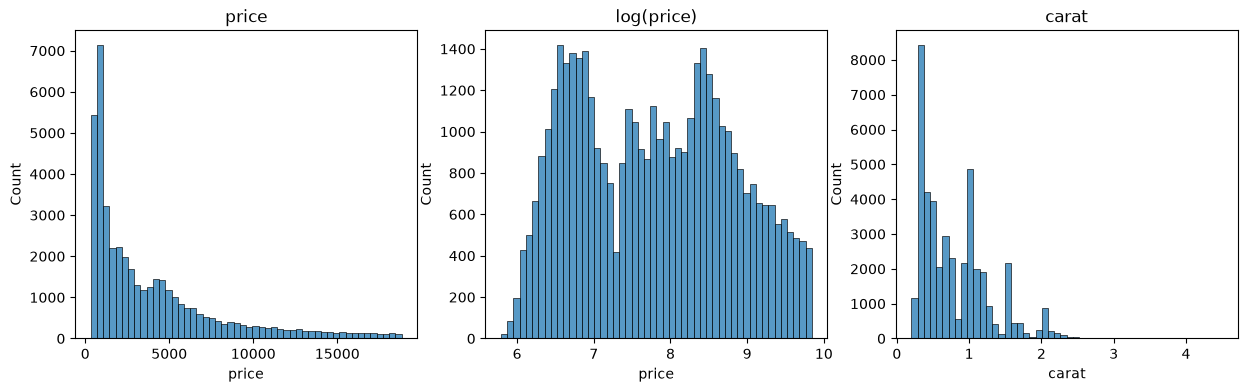

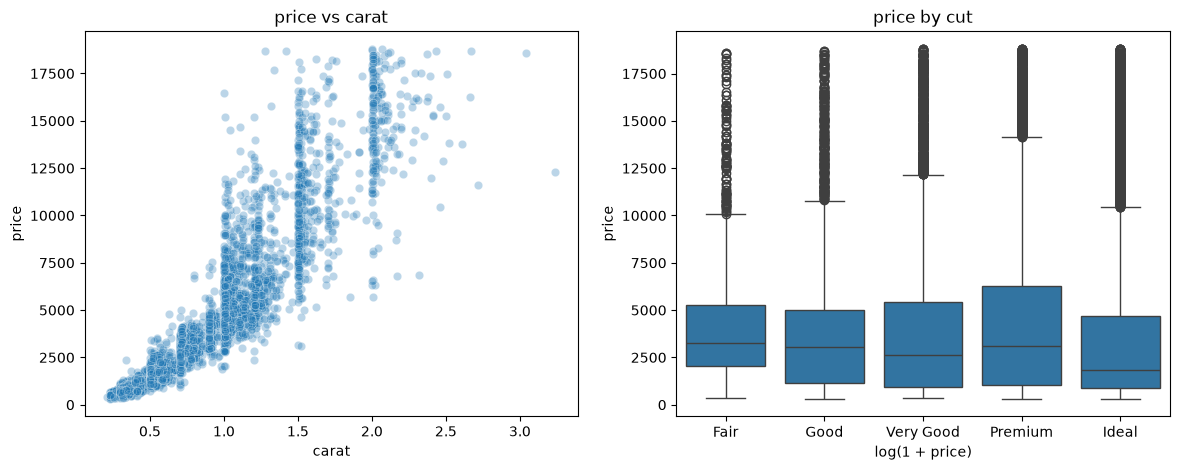

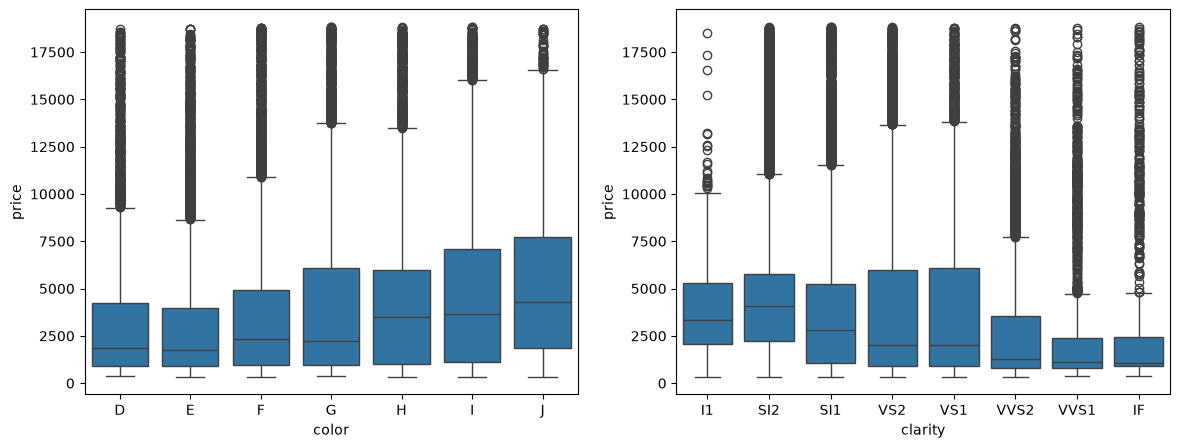

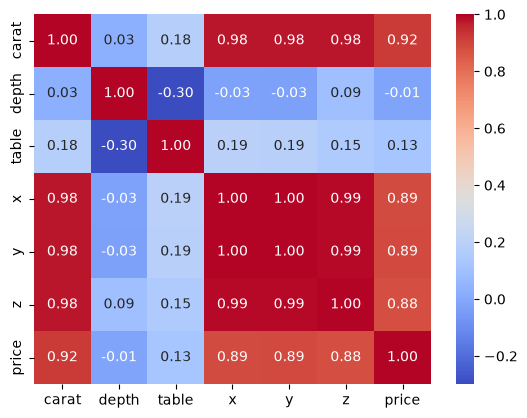

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(train_df.price, bins=50, ax=ax[0]);              ax[0].set_title("price")
sns.histplot(np.log1p(train_df.price), bins=50, ax=ax[1]);    ax[1].set_title("log(price)")
sns.histplot(train_df.carat, bins=50, ax=ax[2]);              ax[2].set_title("carat")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=train_df.sample(5000, random_state=1), x="carat", y="price", alpha=0.3, ax=ax[0])
ax[0].set_title("price vs carat")
sns.boxplot(data=train_df, x="cut", y="price",
            order=["Fair","Good","Very Good","Premium","Ideal"], ax=ax[1])
ax[1].set_title("price by cut")
ax[1].set_xlabel("log(1 + price)")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=train_df, x="color", y="price", order=list("DEFGHIJ"), ax=ax[0])
sns.boxplot(data=train_df, x="clarity", y="price",
            order=["I1","SI2","SI1","VS2","VS1","VVS2","VVS1","IF"], ax=ax[1])
plt.show()

# Multivariate: correlation
sns.heatmap(train_df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

cut
Fair         1.00
Good         0.81
Very Good    0.72
Premium      0.82
Ideal        0.54
Name: carat, dtype: float64 

color
D    0.54
E    0.53
F    0.70
G    0.70
H    0.90
I    1.00
J    1.11
Name: carat, dtype: float64 

clarity
I1      1.10
SI2     1.01
SI1     0.76
VS2     0.62
VS1     0.58
VVS2    0.43
VVS1    0.39
IF      0.36
Name: carat, dtype: float64 



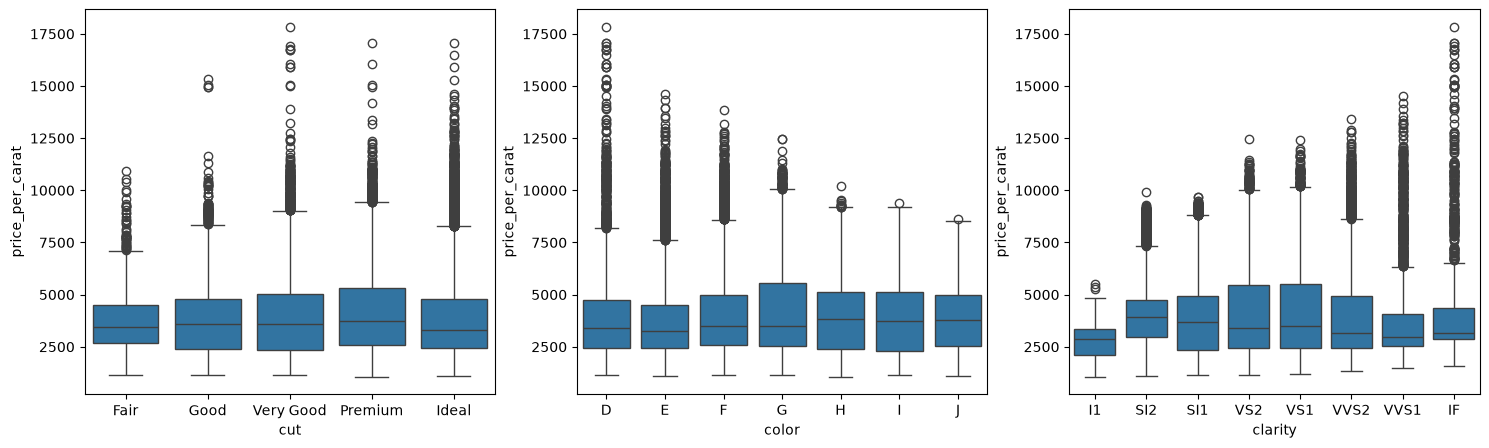

In [11]:
orders = {
    "cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
    "color": list("DEFGHIJ"),
    "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"],
}

for col, order in orders.items():
    print(train_df.groupby(col)["carat"].median().reindex(order).round(2), "\n")

eda = train_df.assign(price_per_carat=train_df.price / train_df.carat)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (col, order) in zip(ax, orders.items()):
    sns.boxplot(data=eda, x=col, y="price_per_carat", order=order, ax=a)
plt.show()

### EDA insights

1. **Price is strongly right-skewed.** Most diamonds are cheap and a long tail reaches about $18.8k. The log of price is less skewed but still has several peaks, which suggests distinct groups of stones.
2. **Carat is the strongest driver of price** (correlation 0.92), but the relationship is curved and the spread grows with size.
3. **Prices jump at round weights.** Carat counts and prices show spikes around 1.0, 1.5 and 2.0 carat.
4. **x, y and z are almost copies of carat** (correlation about 0.98 with carat and about 0.99 with each other), so they carry mostly the same information as size.
5. **Higher quality looks cheaper in raw charts, and this is confounding.** Better cut, color and clarity are found on smaller stones (median carat: Ideal 0.54 vs Fair 1.00; IF 0.36 vs I1 1.10), and size dominates price. Dividing price by carat weakened the effect of quality, but did not show a clean ordering, so we let the model estimate quality's effect.

## 5. Preprocessing pipeline

Everything is inside a scikit-learn Pipeline, so each step is fitted on training data only.
- **Ordinal encoding** for cut, color and clarity with their natural order (color is ordered J to D).
- **Standard scaling** for numeric features (needed by linear regression).
- **Log-transformed target:** models learn on log(price), and predictions are converted back to dollars, so every metric below is in dollars.

## 6. Baseline and candidate models

We compare a baseline (always predict the average price) with Linear Regression, Random Forest and Gradient Boosting, using 5-fold cross-validation on the training set. MAE is the main metric, RMSE and R² are supporting metrics.

The baseline is evaluated without the log transform, so it really predicts the mean price.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate

cut_order     = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order   = ["J", "I", "H", "G", "F", "E", "D"]            # worst -> best
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

cat_cols = ["cut", "color", "clarity"]
num_cols = ["carat", "depth", "table", "x", "y", "z"]

def make_pipeline(model):
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(categories=[cut_order, color_order, clarity_order]), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])
    pipe = Pipeline([("prep", prep), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

models = {
    "Baseline (mean)":   DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest":     RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}

rows = []
for name, m in models.items():
    res = cross_validate(make_pipeline(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name,
                 "MAE":  -res["test_MAE"].mean(),
                 "RMSE": -res["test_RMSE"].mean(),
                 "R2":    res["test_R2"].mean()})

cv_results = pd.DataFrame(rows).round(3)
cv_results

,model,MAE,RMSE,R2
0,Baseline (mean),2814.273,4278.844,-0.146
1,Linear Regression,462.499,895.585,0.950
2,Random Forest,271.979,556.066,0.981
3,HistGradientBoosting,277.794,552.544,0.981


**Cross-validation result (MAE):** Baseline $3,041, Linear Regression $462, Random Forest $272, Gradient Boosting $278. Linear Regression explains a lot (R² 0.95) but misses the non-linear part, while both tree models are much more accurate.

In [13]:
baseline = cross_validate(DummyRegressor(strategy="mean"), X_train, y_train,
                          cv=cv, scoring=scoring)

cv_results.loc[0] = {"model": "Baseline (mean)",
                     "MAE":  -baseline["test_MAE"].mean(),
                     "RMSE": -baseline["test_RMSE"].mean(),
                     "R2":    baseline["test_R2"].mean()}
cv_results.round(3)

,model,MAE,RMSE,R2
0,Baseline (mean),3040.584,3996.787,-0.000
1,Linear Regression,462.499,895.585,0.950
2,Random Forest,271.979,556.066,0.981
3,HistGradientBoosting,277.794,552.544,0.981


## 7. Hyperparameter tuning

Randomized search with 3-fold cross-validation on the training set, optimizing MAE, for Random Forest and Gradient Boosting. Each tuned model is then compared again with the same 5-fold split as the first comparison.

In [14]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

cv3 = KFold(n_splits=3, shuffle=True, random_state=42)

# Random Forest
rf_search = RandomizedSearchCV(
    make_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1)),
    param_distributions={
        "regressor__model__n_estimators":     randint(100, 400),
        "regressor__model__max_depth":        [None, 10, 20, 30],
        "regressor__model__min_samples_leaf": randint(1, 6),
        "regressor__model__max_features":     [0.5, 0.7, 1.0],
    },
    n_iter=12, cv=cv3, scoring="neg_mean_absolute_error",
    random_state=42, n_jobs=1, verbose=1,
)
rf_search.fit(X_train, y_train)
print("RF  best CV MAE:", -rf_search.best_score_)
print(rf_search.best_params_)

# HistGradientBoosting
hgb_search = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingRegressor(random_state=42)),
    param_distributions={
        "regressor__model__learning_rate":     uniform(0.03, 0.17),
        "regressor__model__max_iter":          randint(200, 800),
        "regressor__model__max_leaf_nodes":    randint(15, 63),
        "regressor__model__min_samples_leaf":  randint(10, 60),
        "regressor__model__l2_regularization": uniform(0, 1.0),
    },
    n_iter=20, cv=cv3, scoring="neg_mean_absolute_error",
    random_state=42, n_jobs=1, verbose=1,
)
hgb_search.fit(X_train, y_train)
print("HGB best CV MAE:", -hgb_search.best_score_)
print(hgb_search.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
RF  best CV MAE: 273.1554938959269
{'regressor__model__max_depth': 30, 'regressor__model__max_features': 0.7, 'regressor__model__min_samples_leaf': 2, 'regressor__model__n_estimators': 364}
Fitting 3 folds for each of 20 candidates, totalling 60 fits
HGB best CV MAE: 269.0260114733058
{'regressor__model__l2_regularization': np.float64(0.17052412368729153), 'regressor__model__learning_rate': np.float64(0.04105877080749752), 'regressor__model__max_iter': 587, 'regressor__model__max_leaf_nodes': 39, 'regressor__model__min_samples_leaf': 23}


In [15]:
import joblib, os

tuned = {
    "RF (tuned)":  rf_search.best_estimator_,
    "HGB (tuned)": hgb_search.best_estimator_,
}

rows = []
for name, est in tuned.items():
    res = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({
        "model": name,
        "MAE":      -res["test_MAE"].mean(),
        "MAE_std":   res["test_MAE"].std(),
        "RMSE":     -res["test_RMSE"].mean(),
        "R2":        res["test_R2"].mean(),
    })
print(pd.DataFrame(rows).round(3))

# حجم الملف
for name, est in tuned.items():
    fn = f"tmp_{name.split()[0]}.joblib"
    joblib.dump(est, fn, compress=3)
    print(name, round(os.path.getsize(fn) / 1e6, 1), "MB")
    os.remove(fn)

         model      MAE  MAE_std     RMSE     R2
0   RF (tuned)  269.515    5.622  549.848  0.981
1  HGB (tuned)  267.285    4.993  536.709  0.982
RF (tuned) 185.0 MB
HGB (tuned) 0.6 MB


**Tuned result (5-fold CV MAE):** Random Forest $269.5 (± 5.6), Gradient Boosting $267.3 (± 5.0). The $2 gap is smaller than the fold-to-fold variation, so the two are equally accurate. The tuned Random Forest file is 185 MB versus 0.6 MB for Gradient Boosting, so **Gradient Boosting is the final model** (chosen for size and speed, not because it is more accurate).

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_model = hgb_search.best_estimator_
final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)

base = DummyRegressor(strategy="mean").fit(X_train, y_train)
base_pred = base.predict(X_test)

def scores(y_true, y_pred):
    return {"MAE":  mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2":   r2_score(y_true, y_pred)}

test_results = pd.DataFrame({"Baseline (mean)": scores(y_test, base_pred),
                             "HGB (final)":     scores(y_test, pred)}).T.round(3)
print(test_results)

                      MAE      RMSE     R2
Baseline (mean)  2993.297  3941.418 -0.000
HGB (final)       271.174   534.209  0.982


## 8. Model and feature selection

A web app is easier to use with fewer inputs, so we tested smaller feature sets using cross-validation on the training set. Rule set in advance: accept a smaller set only if its MAE stays within about $5 of the full model.

| Features | CV MAE |
|---|---|
| All 9 features | $267.3 |
| carat, cut, color, clarity | $285.9 (rejected) |
| + x, y, z (7 features) | **$267.2 (accepted)** |
| + depth, table | $279.8 (rejected) |

Depth and table add nothing, while x, y and z are needed. The final model uses 7 features.

                   abs_err  pct_err
price_band                         
(334.999, 830.0]      25.7      4.2
(830.0, 1723.0]       50.2      4.5
(1723.0, 3466.0]     116.6      4.8
(3466.0, 6224.2]     239.4      5.2
(6224.2, 18736.0]    495.3      5.1 

            abs_err  pct_err
carat_band                  
(0.0, 0.5]     33.4      4.4
(0.5, 1.0]    121.6      4.8
(1.0, 1.5]    294.6      5.0
(1.5, 2.0]    574.6      5.3
(2.0, 6.0]   1018.8      6.9 

       actual     pred  abs_err  carat        cut color clarity
9846    18018  11119.0   6899.0    5.0       Fair     J      I1
8638    16193  10315.2   5877.8    3.7    Premium     I      I1
10013   15984  10328.7   5655.3    4.0  Very Good     I      I1
1596    15964  10349.8   5614.2    3.4       Fair     D      I1
4043    15223  10003.7   5219.3    4.0    Premium     I      I1
9882     7188   2553.6   4634.4    1.5       Fair     H     VS2
6597    11379  15768.1   4389.1    1.5  Very Good     F     VS1
2883     8024  12398.9   4374

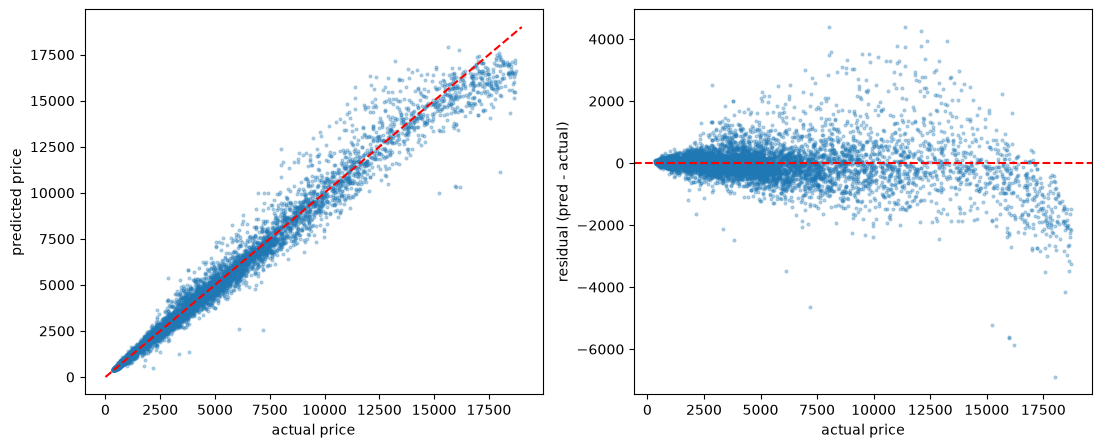

In [17]:
err = pd.DataFrame({"actual": y_test.values, "pred": pred})
err["abs_err"] = (err.pred - err.actual).abs()
err["pct_err"] = err.abs_err / err.actual * 100
err = err.join(X_test.reset_index(drop=True))    

err["price_band"] = pd.qcut(err.actual, 5)
print(err.groupby("price_band", observed=True)[["abs_err", "pct_err"]].median().round(1), "\n")

err["carat_band"] = pd.cut(err.carat, [0, 0.5, 1, 1.5, 2, 6])
print(err.groupby("carat_band", observed=True)[["abs_err", "pct_err"]].median().round(1), "\n")

print(err.sort_values("abs_err", ascending=False)
         .head(10)[["actual", "pred", "abs_err", "carat", "cut", "color", "clarity"]].round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(err.actual, err.pred, s=4, alpha=0.3)
ax[0].plot([0, 19000], [0, 19000], "r--")
ax[0].set_xlabel("actual price"); ax[0].set_ylabel("predicted price")
ax[1].scatter(err.actual, err.pred - err.actual, s=4, alpha=0.3)
ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("actual price"); ax[1].set_ylabel("residual (pred - actual)")
plt.show()

In [18]:
print((X_train.carat > 3).sum(), "train rows with carat > 3")
print(((X_train.carat > 3) & (X_train.clarity == "I1")).sum(), "of them I1")
print((X_train.carat > 2).sum(), "train rows with carat > 2")

print(err.loc[9882])
print(train_df[train_df.carat.between(1.45, 1.55)][["x", "y", "z", "depth", "table"]].describe().round(2))

20 train rows with carat > 3
13 of them I1
1502 train rows with carat > 2
actual                     7188
pred                2553.631647
abs_err             4634.368353
pct_err               64.473683
carat                      1.51
cut                        Fair
color                         H
clarity                     VS2
depth                      65.6
table                      56.0
x                          7.08
y                           4.7
z                           4.0
price_band    (6224.2, 18736.0]
carat_band           (1.5, 2.0]
Name: 9882, dtype: object
             x        y        z    depth    table
count  2039.00  2039.00  2039.00  2039.00  2039.00
mean      7.34     7.33     4.54    61.90    58.26
std       0.11     0.12     0.10     1.65     2.28
min       6.85     6.76     1.53    55.80    52.00
25%       7.27     7.27     4.50    61.00    57.00
50%       7.34     7.33     4.55    62.00    58.00
75%       7.41     7.41     4.58    62.80    60.00
max       7.

## 9. Final test evaluation

The test set is used only now. Note that it was evaluated twice (the 9-feature model, then the 7-feature model); the choice of 7 features was made by cross-validation before the second evaluation.

In [19]:
def make_pipeline_v2(model, num_cols):
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(categories=[cut_order, color_order, clarity_order]), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])
    pipe = Pipeline([("prep", prep), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

feats4 = ["carat", "cut", "color", "clarity"]

est4 = make_pipeline_v2(HistGradientBoostingRegressor(random_state=42), ["carat"])
est4.set_params(**hgb_search.best_params_)     # نفس الـ hyperparameters بتاعة النسخة الكاملة

res4 = cross_validate(est4, X_train[feats4], y_train, cv=cv, scoring=scoring, n_jobs=1)
print("4-feature CV MAE:", -res4["test_MAE"].mean(), "+/-", res4["test_MAE"].std())
print("4-feature CV RMSE:", -res4["test_RMSE"].mean())
print("4-feature CV R2:", res4["test_R2"].mean())

4-feature CV MAE: 285.9103903461532 +/- 6.678295859511612
4-feature CV RMSE: 557.4486879541939
4-feature CV R2: 0.9805257559974485


In [20]:
sets = {
    "4 + x,y,z":      ["carat", "x", "y", "z"],
    "4 + depth,table": ["carat", "depth", "table"],
}

rows = []
for name, nums in sets.items():
    feats = ["cut", "color", "clarity"] + nums
    est = make_pipeline_v2(HistGradientBoostingRegressor(random_state=42), nums)
    est.set_params(**hgb_search.best_params_)
    res = cross_validate(est, X_train[feats], y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"features": name,
                 "MAE": -res["test_MAE"].mean(),
                 "MAE_std": res["test_MAE"].std(),
                 "RMSE": -res["test_RMSE"].mean(),
                 "R2": res["test_R2"].mean()})
print(pd.DataFrame(rows).round(3))

          features      MAE  MAE_std     RMSE     R2
0        4 + x,y,z  267.222    5.177  537.193  0.982
1  4 + depth,table  279.829    6.549  546.847  0.981


On unseen diamonds the final model's average error is **$268**, compared with $2,993 for the baseline (91% lower), with R² = 0.982. This is consistent with the cross-validation estimate ($267), so there is no sign of overfitting to the validation folds.

## 10. Error analysis

Where does the final 7-feature model go wrong?

In [ ]:
import joblib, json, os, sklearn

feats7 = ["cut", "color", "clarity", "carat", "x", "y", "z"]
nums7  = ["carat", "x", "y", "z"]

est7 = make_pipeline_v2(HistGradientBoostingRegressor(random_state=42), nums7)
est7.set_params(**hgb_search.best_params_)
est7.fit(X_train[feats7], y_train)

pred7 = est7.predict(X_test[feats7])
test_results.loc["HGB 7-feature (final)"] = scores(y_test, pred7)
print(test_results.round(3))

# حفظ الموديل
joblib.dump(est7, "diamond_model.joblib", compress=3)
print("size MB:", round(os.path.getsize("diamond_model.joblib") / 1e6, 2))

ranges = X_train[nums7].agg(["min", "max"]).to_dict()
with open("input_ranges.json", "w") as f:
    json.dump(ranges, f, indent=2)

# اختبار إن الملف بيتحمّل وبيتوقع
loaded = joblib.load("diamond_model.joblib")
sample = pd.DataFrame([{"carat": 0.9, "cut": "Ideal", "color": "G",
                        "clarity": "VS2", "x": 6.2, "y": 6.2, "z": 3.8}])
print("sample prediction:", loaded.predict(sample[feats7]))

import pandas, numpy
print("sklearn", sklearn.__version__, "| pandas", pandas.__version__, "| numpy", numpy.__version__)

                             MAE       RMSE      R2
Baseline (mean)       2,993.2970 3,941.4180 -0.0000
HGB (final)             271.1740   534.2090  0.9820
HGB 7-feature (final)   267.9280   529.6560  0.9820
size MB: 1.15
sample prediction: [4467.49103705]
sklearn 1.9.0 | pandas 3.0.3 | numpy 2.4.6


In [ ]:
err = pd.DataFrame({"actual": y_test.values, "pred": pred7})
err["abs_err"] = (err.pred - err.actual).abs()
err["pct_err"] = err.abs_err / err.actual * 100
err = err.join(X_test.reset_index(drop=True))

err["price_band"] = pd.qcut(err.actual, 5)
print(err.groupby("price_band", observed=True)[["abs_err", "pct_err"]].median().round(1), "\n")

err["carat_band"] = pd.cut(err.carat, [0, 0.5, 1, 1.5, 2, 6])
print(err.groupby("carat_band", observed=True)[["abs_err", "pct_err"]].median().round(1), "\n")

print(err.sort_values("abs_err", ascending=False)
         .head(10)[["actual", "pred", "abs_err", "carat", "cut", "color", "clarity"]].round(1), "\n")

print("MAE reduction vs baseline:", round((1 - 267.928 / 2993.297) * 100, 1), "%")
print("share of test stones above 2 carat:", round((err.carat > 2).mean() * 100, 1), "%")
print("mean pct error:", round(err.pct_err.mean(), 1), "%")
print("underpredicted share:", round((err.pred < err.actual).mean() * 100, 1), "%")

                   abs_err  pct_err
price_band                         
(334.999, 830.0]   22.2000   3.5000
(830.0, 1723.0]    47.8000   4.2000
(1723.0, 3466.0]  117.0000   4.8000
(3466.0, 6224.2]  241.5000   5.2000
(6224.2, 18736.0] 491.9000   5.1000 

            abs_err  pct_err
carat_band                  
(0.0, 0.5]  30.0000   3.9000
(0.5, 1.0] 119.9000   4.8000
(1.0, 1.5] 295.4000   4.9000
(1.5, 2.0] 587.4000   5.4000
(2.0, 6.0] 999.9000   6.6000 

       actual        pred    abs_err  carat        cut color clarity
9846    18018 10,971.7000 7,046.3000 5.0000       Fair     J      I1
10013   15984 10,183.2000 5,800.8000 4.0000  Very Good     I      I1
8638    16193 10,492.7000 5,700.3000 3.7000    Premium     I      I1
1596    15964 10,848.1000 5,115.9000 3.4000       Fair     D      I1
4043    15223 10,492.7000 4,730.3000 4.0000    Premium     I      I1
9882     7188  2,669.7000 4,518.3000 1.5000       Fair     H     VS2
6597    11379 15,868.8000 4,489.8000 1.5000  Very Good    

**Findings**
- The typical relative error is steady across price levels (median 3.5% to 5.2%), but the dollar error grows with price (median $22 for the cheapest fifth, $492 for the most expensive).
- The error is larger for big stones: median 6.6% (about $1,000) above 2 carat.
- The five largest errors are all large (3.4 to 5 carat), low-clarity (I1) stones, under-priced by about $4,700 to $7,000. The training data has only 20 rows above 3 carat.
- Overall 51.6% of predictions are below the true price, so there is no systematic bias in one direction.
- One of the largest errors (row with actual price $7,188) comes from a row whose dimensions are inconsistent with its carat weight. This is a data-quality issue our cleaning rule did not catch.

In [ ]:
ratio = X_train.carat / (X_train.x * X_train.y * X_train.z)
ranges = X_train[nums7].agg(["min", "max"]).to_dict()
ranges["_ratio"] = {"ratio_lo": float(ratio.quantile(0.001)),
                    "ratio_hi": float(ratio.quantile(0.999))}
with open("input_ranges.json", "w") as f:
    json.dump(ranges, f, indent=2)
print(ranges["_ratio"])

{'ratio_lo': 0.00577065271575972, 'ratio_hi': 0.006828119432970752}


In [ ]:
import sys, os
print(sys.executable)
print(os.getcwd())

c:\ProgramData\anaconda3\python.exe
c:\Users\AS\Downloads\Compressed\archive


## 12. Saving the model for the app

The final pipeline is saved with joblib, together with the input ranges used by the app to reject impossible values. The app is a Streamlit page deployed on Streamlit Community Cloud.

## Data credit

Diamonds dataset, originally from the R package ggplot2 (Wickham). CSV copy on Kaggle (shivam2503/diamonds). The dataset is not redistributed in this repository.

## Business insight

**What the results mean.** On diamonds it had never seen, the model's average
error is about $268, compared with about $2,993 when we simply guess the average
price, which is 91% lower. A jeweler can use it as a fast first estimate for
listing prices and as a sanity check on a supplier's asking price.

**Where to trust it.** The typical (median) error is a similar share of the price
at every price level, about 3.5% to 5.2%. In dollars it grows with price, from a
median of about $22 on the cheapest fifth of diamonds to about $492 on the most
expensive fifth. The mean error (6.4%) is higher than these medians because a few
large misses pull it up.

**Where to be careful.**
- Stones above 2 carat have a larger error (median 6.6%, about $1,000) and make
  up only 3.4% of the test set. The training data has just 20 rows above 3 carat,
  13 of them clarity I1.
- The five largest errors are all large (3.4 to 5 carat), low-clarity (I1) stones
  that the model under-priced by about $4,700 to $7,000.
- Across the whole test set, 51.6% of predictions are below the true price, so the
  model is not biased in one direction overall.

**Recommended next steps for the business.**
1. Use the model for first-pass pricing, and send stones above 2 carat, and
   anything the app's consistency check rejects, to manual appraisal.
2. Collect more large and low-clarity examples and retrain.
3. Show a price range instead of a single number (future work).

**Limitations.**
- The data is a fixed historical snapshot, not live market prices, so the model
  must be retrained before use on current prices.
- The dataset tops out around $18.8k, so the model should not be used above that.
- Only certificate attributes are used (carat, cut, color, clarity, size).
  Fluorescence, the grading lab and market conditions are not included.
- The raw data contains rows with inconsistent dimensions that our cleaning rule
  did not catch. The sixth-largest test error ($4,518) comes from one such row.
  We left the test set untouched.
- The test set was evaluated twice (9 features, then 7 features). The choice of 7
  features was made by cross-validation before the second evaluation.